# Análisis exploratorio de datos de Iris

## 1. Dataset y objetivo

In [1]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df = iris.frame.copy()

df_original = df.copy(deep=True)

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


El análisis exploratorio de datos (EDA) sirve para conocer la estructura, la calidad y los patrones de un conjunto antes de sacar conclusiones o construir modelos. En Iris analizo cómo varían las medidas y si la longitud del pétalo ayuda a distinguir las especies.

El conjunto clásico de Iris se asocia al trabajo de R. A. Fisher. La versión de scikit-learn incluye 150 flores de tres especies. Se distribuye con la biblioteca y se puede cargar sin descargar un CSV. Con `as_frame=True`, `iris.frame` reúne las cuatro medidas y la etiqueta en un DataFrame. Guardo una copia independiente en `df_original` para comparar después. [Documentación de load_iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)

## 2. Primera revisión

In [2]:

print("Dimensiones:", df.shape)

print("Número de registros:", df.shape[0])

print("Número de variables:", df.shape[1])

print("Columnas:", df.columns.tolist())

print("Tipos de datos:")
print(df.dtypes)

print("Primeras filas:")
print(df.head())


Dimensiones: (150, 5)
Número de registros: 150
Número de variables: 5
Columnas: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']
Tipos de datos:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object
Primeras filas:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


`df.shape ` devuelve una tupla con dos elementos (filas, columnas)

`df.columns.tolist` muestra el nombre de la columna

Cada fila representa una flor y cada columna, una característica o su especie. Una *feature* es una característica medida. Aquí las cuatro medidas son las *features* y `target` es la etiqueta. Las primeras filas muestran la estructura y ejemplos de valores. El equilibrio entre especies, los rangos y los nulos requieren comprobar las 150 filas.

## 3. Diccionario de variables

Las cuatro medidas en centímetros son numéricas continuas. El redondeo a una cifra decimal limita la precisión registrada, pero la longitud y la anchura pueden tomar valores intermedios. Una variable discreta toma valores separados, como un conteo de pétalos.

`target` es nominal. Los enteros 0, 1 y 2 codifican Setosa, Versicolor y Virginica, sin orden ni distancia entre especies. Una variable ordinal sí tiene un orden, como bajo, medio y alto. Un identificador distinguiría registros individuales, mientras que estas etiquetas se repiten entre flores de una misma especie.

In [3]:

tabla_variables = pd.DataFrame({
    "Variable": df.columns,
    "Significado": [
        "Longitud del sépalo",
        "Anchura del sépalo",
        "Longitud del pétalo",
        "Anchura del pétalo",
        "Especie de la flor"
    ],
    "Unidad": ["cm", "cm", "cm", "cm", "No aplica"],
    "Tipo Python": df.dtypes.values,
    "Tipo estadístico": [
        "Numérica continua",
        "Numérica continua",
        "Numérica continua",
        "Numérica continua",
        "Categórica nominal"
    ]
})

display(tabla_variables)


,Variable,Significado,Unidad,Tipo Python,Tipo estadístico
0,sepal length (cm),Longitud del sépalo,cm,float64,Numérica continua
1,sepal width (cm),Anchura del sépalo,cm,float64,Numérica continua
2,petal length (cm),Longitud del pétalo,cm,float64,Numérica continua
3,petal width (cm),Anchura del pétalo,cm,float64,Numérica continua
4,target,Especie de la flor,No aplica,int64,Categórica nominal


`pd.DataFrame` crea una tabla de pandas.

`df.columns` obtiene el nombre de las columnas.

`df.dtypes.values` Obtiene los tipos de datos de esas columnas.

`display` muestra la tabla con formato visual en Colab.

## 4. Detección de errores

Compruebo los tipos, los rangos, los códigos de especie y las filas coincidentes antes de modificar una copia.

In [4]:
print(df.dtypes)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object


`df.dtypes` devuelve el tipo de dato de cad columna.
Usamos esto para ver si el formato del dato a mostrar es el correcto / tiene sentido usar ese tipo de dato.

In [5]:
columnas_numericas = df.columns[:4]

print((df[columnas_numericas] <= 0).sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


seleccionamos las primeras 4 columnas que contienen las medidas y luego comprobamos si los valores son menores o iguales a cero. Si da con un valor menor o igual, se suma.

Si por consola aparece al lado de la columna un número mayor a cero significa que hay valores 0 o inferiores

In [6]:
duplicados = df.duplicated()

print("Número de filas duplicadas:", duplicados.sum())

Número de filas duplicadas: 1


`df.duplicated()` Comprueba si una fila tiene los mismos valores que otra anterior.
Con la variable `duplicados` guardamos una serie de valores booleanos y con `duplicados.sum()` sumara solamente los valores True.

In [7]:
filas_repetidas = df[df.duplicated(keep=False)]

display(filas_repetidas)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


`keep=False` Marca todas las apariciones de una fila repetida, incluida la primera

In [8]:
print(df.iloc[:, :4].agg(["min", "max"]))

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
min                4.3               2.0                1.0               0.1
max                7.9               4.4                6.9               2.5


`.agg()` permite aplicar varias funciones de agregación.
`"min" y "max"` argumento que pasamos al método

### Apartado 4 — Revisión de errores

**Tipos de datos:** Las cuatro variables de medidas están almacenadas como `float64` y la variable `target` como `int64`. Sus tipos son coherentes con los datos representados.

**Valores imposibles:** Se han comprobado las medidas menores o iguales a cero. Se han revisado también los valores mínimos y máximos para identificar posibles incoherencias.

**Registros duplicados:** Se ha detectado una fila coincidente con otra. He decidido conservar ambas porque pueden representar dos flores diferentes y no existe información suficiente para confirmar un error.

**Decisiones de limpieza:** No se han eliminado registros. Se documentará cualquier corrección adicional que resulte necesaria.

Las filas con índices 101 y 142 tienen medidas y especie iguales. Se conservaron las 150 filas, con 0 correcciones y 0 bajas. La documentación identifica las cuatro medidas en cm. La positividad y los rangos observados sirven para detectar incoherencias evidentes. La coherencia de la unidad depende de la documentación de origen.

In [9]:
print(df["target"].value_counts().sort_index())

target
0    50
1    50
2    50
Name: count, dtype: int64


`df["target"]` seleccionamos la columna en concreto.
`.value_counts()` cuanta cuántas veces aparece cada código.
`.sort_index()` ordena el resultado por el código de la especie.

## 5. Datos faltantes

Compruebo cuántas observaciones faltan por columna y si hay textos vacíos o códigos especiales.

In [10]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


`df.isnull()` marca las ausencias reconocidas por pandas. Al sumar los booleanos por columna obtengo el recuento.

In [11]:
porcentaje_nulos = df.isnull().sum() / len(df) * 100

print(porcentaje_nulos)

sepal length (cm)    0.0
sepal width (cm)     0.0
petal length (cm)    0.0
petal width (cm)     0.0
target               0.0
dtype: float64


al multiplicarlo por 100 se convierte en porcentaje

In [12]:

import numpy as np

ejemplo = pd.Series([
    10,
    np.nan,
    None,
    "",
    "   ",
    0
])

print(ejemplo.isnull())


0    False
1     True
2     True
3    False
4    False
5    False
dtype: bool


`np.nan` representa un valor NaN.

`None` representa la ausencia de un objeto en Python.

`""` es un texto vacío.

`"   "` contiene tres espacios.

`0` es un número válido, no un valor faltante.

`pd.Series()` crea una estructura unidimensional de pandas.

In [13]:

for columna in df.columns:
    vacios = df[columna].astype("string").str.strip().eq("").sum()
    print(f"{columna}: {vacios} textos vacíos")


sepal length (cm): 0 textos vacíos
sepal width (cm): 0 textos vacíos
petal length (cm): 0 textos vacíos
petal width (cm): 0 textos vacíos
target: 0 textos vacíos


Con `astype("string")` convierto temporalmente a texto, con `str.strip()` quito espacios en los extremos y con `.eq("")` detecto cadenas vacías. Una cadena vacía o de espacios requiere una comprobación adicional a `isnull()`.

In [14]:
codigos_especie = set(range(len(iris.target_names)))
codigos_inesperados = set(df["target"].dropna()) - codigos_especie
print("Códigos de especie fuera del catálogo:", sorted(codigos_inesperados))
print("Valores infinitos por medida:")
print(np.isinf(df[columnas_numericas]).sum())

Códigos de especie fuera del catálogo: []
Valores infinitos por medida:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


No se encontraron códigos de especie fuera del catálogo ni medidas infinitas o no positivas. El código 0 significa Setosa. La comprobación de códigos depende del dominio documentado: un valor numérico plausible podría pasar estos controles si la fuente no indica que representa una ausencia.

## 6. Simulación de ausencias

In [15]:
df_trabajo = df.copy(deep=True)

print(df_trabajo.shape)

(150, 5)


Con `copy(deep=True)` crea una copia independiente de los datos.

In [16]:
import numpy as np

rng = np.random.default_rng(seed=42)

filas_numericas = rng.choice(df_trabajo.index, size=10, replace=False)

filas_categoricas = rng.choice(df_trabajo.index, size=5, replace=False)

print("Filas numéricas:", filas_numericas)
print("Filas categóricas:", filas_categoricas)

Filas numéricas: [146 109  12  93  63  62 103  14  30 125]
Filas categóricas: [ 65 139  73  54  27]


`rng = np.random.default_rng(seed=42)` Creamos un generador aleatorio. La semilla 42 permite obtener los mismos resultados al repetir el código.

con `size=` seleccioanmos cuantas filas alteraremos y con `replace = False` evitamos que una misma fila se seleccione dos veces.

Con `seed =` generamos números *pseudoaleatorios* mediante algoritmos matemáticos.

In [17]:
df_trabajo.loc[filas_numericas, "sepal length (cm)"] = np.nan

df_trabajo.loc[filas_categoricas, "target"] = np.nan

print(df_trabajo.isnull().sum())


sepal length (cm)    10
sepal width (cm)      0
petal length (cm)     0
petal width (cm)      0
target                5
dtype: int64


`.loc[]` permite seleccionar filas y columnas mediante sus etiquetas.

`filas_numericas` contiene los índices de las 10 filas seleccionadas.

`np.nan` representa el valor faltante que introduciremos.


Realizamos este código para seleccionar aleatoriamente filas del dataset Iris donde posteriormente introduciremos valores NaN, simulando datos faltantes.

Como Iris no contiene valores nulos, necesitamos crearlos artificialmente para practicar su tratamiento en los siguientes apartados.



In [18]:
comparacion = pd.DataFrame({
    "Valor original": df_original.loc[
        filas_numericas, "sepal length (cm)"
    ],
    "Valor modificado": df_trabajo.loc[
        filas_numericas, "sepal length (cm)"
    ]
})

display(comparacion)

,Valor original,Valor modificado
146,6.3,NaN
109,7.2,NaN
12,4.8,NaN
93,5.0,NaN
63,6.1,NaN
62,6.0,NaN
103,6.3,NaN
14,5.8,NaN
30,4.8,NaN
125,7.2,NaN


In [19]:

comparacion_categorica = pd.DataFrame({
    "Valor original": df_original.loc[filas_categoricas, "target"],
    "Valor modificado": df_trabajo.loc[filas_categoricas, "target"]
})

display(comparacion_categorica)


,Valor original,Valor modificado
65,1,NaN
139,2,NaN
73,1,NaN
54,1,NaN
27,0,NaN


## 7. Tratamiento de ausencias

In [20]:

media = df_trabajo["sepal length (cm)"].mean()

mediana = df_trabajo["sepal length (cm)"].median()

moda = df_trabajo["target"].mode()

print("Media:", media)
print("Mediana:", mediana)
print("Moda:", moda)


Media: 5.835714285714285
Mediana: 5.75
Moda: 0    0.0
1    2.0
Name: target, dtype: float64


Antes de imputar los datos faltantes, calculamos la media, mediana y moda para determinar qué método es más adecuado según el tipo de variable y la presencia de valores atípicos. Así evitamos introducir valores poco representativos que puedan alterar nuestro análisis.

In [21]:

print(df_trabajo["target"].value_counts())


target
0.0    49
2.0    49
1.0    47
Name: count, dtype: int64


In [22]:
df_imputado = df_trabajo.copy(deep=True)

df_imputado["sepal length (cm)"] = (
    df_imputado["sepal length (cm)"].fillna(media)
)

print(df_imputado.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               5
dtype: int64


Creo otra copia para conservar el escenario con ausencias. `fillna(media)` rellena las diez longitudes faltantes con la media de los 140 valores observados. Quedan 0 nulos en longitud del sépalo y 5 en `target`.

In [23]:
comparacion_imputacion = pd.DataFrame({
    "Original": df_original.loc[filas_numericas, "sepal length (cm)"],
    "Imputado": df_imputado.loc[filas_numericas, "sepal length (cm)"]
})

comparacion_imputacion["Error absoluto"] = abs(
    comparacion_imputacion["Original"] - comparacion_imputacion["Imputado"]
)

display(comparacion_imputacion)

,Original,Imputado,Error absoluto
146,6.3,5.835714,0.464286
109,7.2,5.835714,1.364286
12,4.8,5.835714,1.035714
93,5.0,5.835714,0.835714
63,6.1,5.835714,0.264286
62,6.0,5.835714,0.164286
103,6.3,5.835714,0.464286
14,5.8,5.835714,0.035714
30,4.8,5.835714,1.035714
125,7.2,5.835714,1.364286


`abs()` calcula la diferencia abosluta entre ambas, sin signo negativo

In [24]:
error_medio = comparacion_imputacion["Error absoluto"].mean()

print("Error absoluto medio:", error_medio, "cm")

Error absoluto medio: 0.702857142857143 cm


In [25]:
print(df_imputado.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               5
dtype: int64


Para `target` recupero las etiquetas desde `df_original`. La moda está empatada entre Setosa y Virginica (49 observaciones cada una). Elegir una de ellas asignaría etiquetas sin evidencia y alteraría las frecuencias.

In [26]:
df_imputado.loc[filas_categoricas, "target"] = (
    df_original.loc[filas_categoricas, "target"]
)

print(df_imputado.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


Esto no es una imputación estadística ya que recuperamos los datos a traves del `df_original`.

In [27]:
comparacion_nulos = pd.DataFrame({
    "Antes": df_trabajo.isnull().sum(),
    "Después": df_imputado.isnull().sum()
})

display(comparacion_nulos)

,Antes,Después
sepal length (cm),10,0
sepal width (cm),0,0
petal length (cm),0,0
petal width (cm),0,0
target,5,0


In [28]:
originales_ocultos = df_original.loc[filas_numericas, "sepal length (cm)"]
comparacion_metodos = pd.DataFrame({
    "Valor de relleno (cm)": [media, mediana],
    "Error absoluto medio (cm)": [
        (originales_ocultos - media).abs().mean(),
        (originales_ocultos - mediana).abs().mean(),
    ],
}, index=["Media", "Mediana"])
display(comparacion_metodos.round(4))

,Valor de relleno (cm),Error absoluto medio (cm)
Media,5.8357,0.7029
Mediana,5.7500,0.7300


Imputar consiste en sustituir un valor ausente por una estimación. La media resume el centro de una medida numérica y es sensible a extremos. La mediana es más resistente. La moda sirve para categorías y puede tener empates. Mantengo la media porque en estas posiciones dio un error absoluto medio de 0,7029 cm, frente a 0,7300 cm con la mediana. La comparación de errores solo corresponde a estas diez ausencias simuladas y sirve para comprobar cuánto influye cambiar el método.

Cuando el valor original está disponible, recuperarlo evita introducir una estimación. Si falta y no se puede recuperar, conservar el nulo preserva la incertidumbre. Eliminar filas reduce la muestra y puede sesgarla si la ausencia tiene un patrón. Eliminar una columna tendría sentido si la falta de información hace que apenas resulte utilizable.

## 8. Estadística descriptiva

In [29]:
columnas_numericas = df_imputado.columns[:4]

print(df_imputado[columnas_numericas].describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.835714          3.057333           3.758000   
std             0.798831          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.125000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


`.describe()`calcula un resumen estadístico.

**count** Número de valores no nulos

**mean**	Media aritmética

**std**	Desviación estándar

**min**	Valor mínimo

**25%**	Primer cuartil

**50%**	Mediana

**75%**	Tercer cuartil

**max**	Valor máximo

In [30]:
print("Varianza:")
print(df_imputado[columnas_numericas].var())

print("\nDesviación estándar:")
print(df_imputado[columnas_numericas].std())


Varianza:
sepal length (cm)    0.638130
sepal width (cm)     0.189979
petal length (cm)    3.116278
petal width (cm)     0.581006
dtype: float64

Desviación estándar:
sepal length (cm)    0.798831
sepal width (cm)     0.435866
petal length (cm)    1.765298
petal width (cm)     0.762238
dtype: float64


La varianza muestral mide la dispersión usando las diferencias cuadráticas respecto a la media y se expresa en cm². Su raíz es la desviación estándar, que se expresa en cm.

In [31]:
print(df_imputado.mode())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0           5.835714               3.0                1.4               0.2   
1                NaN               NaN                1.5               NaN   
2                NaN               NaN                NaN               NaN   

   target  
0     0.0  
1     1.0  
2     2.0  


Si hay un empate, informo todas las modas. La longitud del pétalo tiene dos (1,4 y 1,5 cm) y `target` tiene tres. Los `NaN` de esta salida rellenan posiciones en las que una columna ya no tiene más modas. Para la especie interpreto frecuencias, proporciones y modas. La media, la varianza y los cuartiles de los códigos no tienen interpretación estadística como medidas de especie.

In [32]:
comparacion_estadisticas = pd.DataFrame({
    "Antes de imputar": df_trabajo["sepal length (cm)"].describe(),
    "Despues de imputar": df_imputado["sepal length (cm)"].describe()
})

display(comparacion_estadisticas)

,Antes de imputar,Despues de imputar
count,140.000000,150.000000
mean,5.835714,5.835714
std,0.827067,0.798831
min,4.300000,4.300000
25%,5.100000,5.125000
50%,5.750000,5.800000
75%,6.400000,6.400000
max,7.900000,7.900000


In [33]:
std_antes = df_trabajo["sepal length (cm)"].std()
std_despues = df_imputado["sepal length (cm)"].std()

print("Desviacion antes: ", std_antes)
print("Desviacion después: ", std_despues)
print("Diferencia: ", std_despues - std_antes)

Desviacion antes:  0.8270665356975269
Desviacion después:  0.7988306410603169
Diferencia:  -0.02823589463720999


Al rellenar con la media de los datos observados, esta se mantiene en 5,8357 cm y la desviación baja de 0,8271 a 0,7988 cm. Se añadieron diez valores iguales a la media, lo que concentra observaciones en el centro. La moda de 5,8357 cm de esta medida también es producto del relleno.

In [34]:
resumen_especies = pd.DataFrame({
    "Antes del tratamiento": df_trabajo["target"].value_counts(dropna=False),
    "Después del tratamiento": df_imputado["target"].value_counts(dropna=False),
}).fillna(0).astype(int)
resumen_especies.index = ["Sin etiqueta" if pd.isna(x) else iris.target_names[int(x)]
                         for x in resumen_especies.index]
display(resumen_especies)

,Antes del tratamiento,Después del tratamiento
setosa,49,50
versicolor,47,50
virginica,49,50
Sin etiqueta,5,0


Las frecuencias pasan de 49 Setosa, 47 Versicolor y 49 Virginica, con 5 etiquetas ausentes, a 50 flores de cada especie al restaurar las etiquetas.

## 9. Histogramas y barras

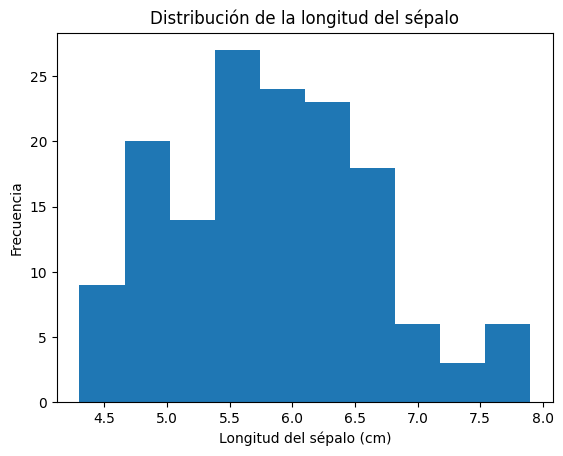

In [35]:
import matplotlib.pyplot as plt

plt.hist(df_imputado["sepal length (cm)"], bins=10)

plt.title("Distribución de la longitud del sépalo")
plt.xlabel("Longitud del sépalo (cm)")
plt.ylabel("Frecuencia")

plt.show()

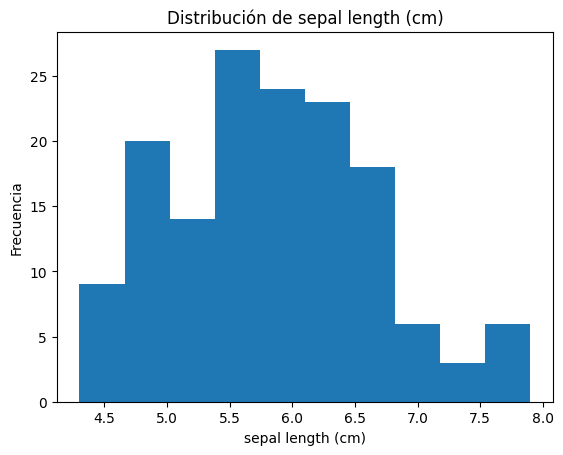

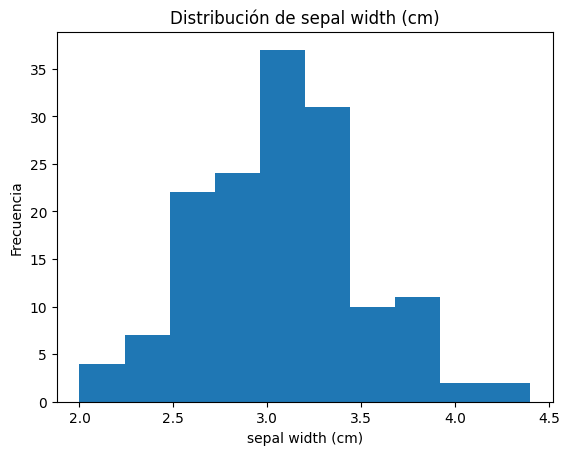

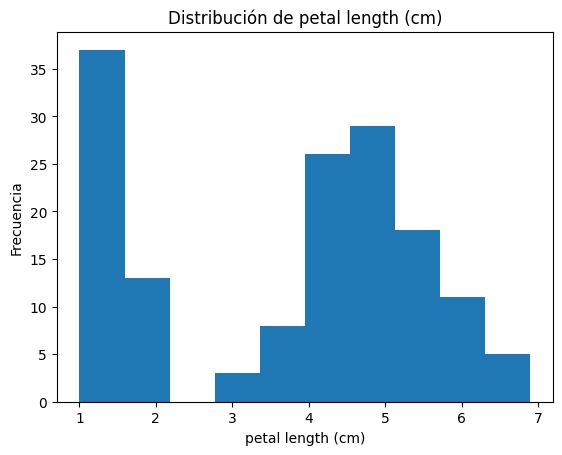

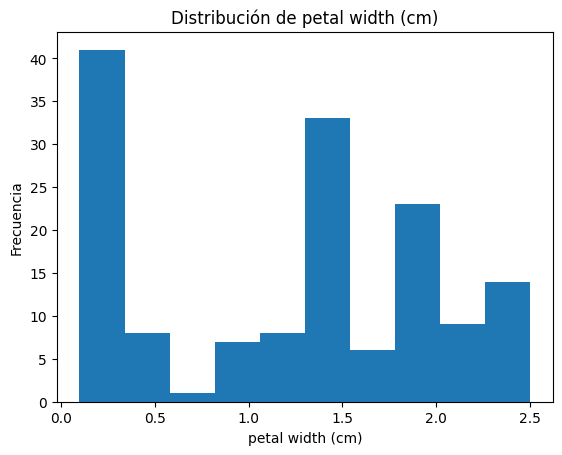

In [36]:

for columna in columnas_numericas:
    plt.hist(df_imputado[columna], bins=10)

    plt.title(f"Distribución de {columna}")
    plt.xlabel(columna)
    plt.ylabel("Frecuencia")

    plt.show()


`import matplotlib.pyplot as plt`	Importa las herramientas para crear gráficos.

`plt.hist()`	Genera un histograma de los valores numéricos.

`bins=10`	Divide el rango de los datos en 10 intervalos.

plt.title()	Añade un título al gráfico.

`plt.xlabel()`	Etiqueta el eje horizontal (X).

`plt.ylabel()`	Etiqueta el eje vertical (Y).

`plt.show()`	Muestra el gráfico.

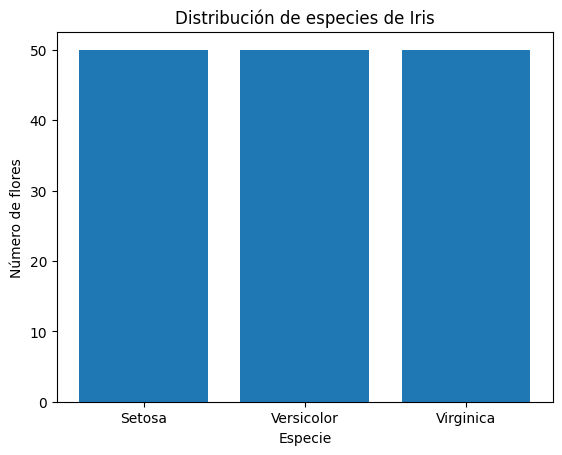

In [37]:
frecuencias = df_imputado["target"].value_counts().sort_index()

plt.bar(["Setosa", "Versicolor", "Virginica"], frecuencias)

plt.title("Distribución de especies de Iris")
plt.xlabel("Especie")
plt.ylabel("Número de flores")

plt.show()


**¿Qué es la asimetría?**
La asminetría indica si los valores se distribuyen de forma equilibrada alrededor del centro o si se concentran más hacia uno de los lados

**Simétrica**: los valores se distribuyen aproximadamente de forma equilibrada a ambos lados del centro.

**Asimetría positiva**: presenta una cola más larga hacia los valores altos.

**Asimetría negativa**: presenta una cola más larga hacia los valores bajos.

El eje X de un histograma contiene intervalos de una medida y el eje Y cuenta cuántas flores caen en cada intervalo. Una barra categórica representa una especie. Los bins más anchos suavizan el gráfico y pueden ocultar agrupaciones. Los más estrechos muestran más detalle, con más fluctuaciones. La anchura del sépalo se concentra alrededor de 3 cm, con una cola que llega hacia 4,4 cm. La longitud del sépalo muestra una concentración más amplia cerca de 5–6,5 cm. Las dos medidas del pétalo muestran agrupaciones, especialmente la longitud, que deja un hueco entre la concentración de pétalos cortos y el resto. Las tres especies tienen la misma frecuencia tras recuperar las etiquetas.

## 10. Boxplots y criterio IQR

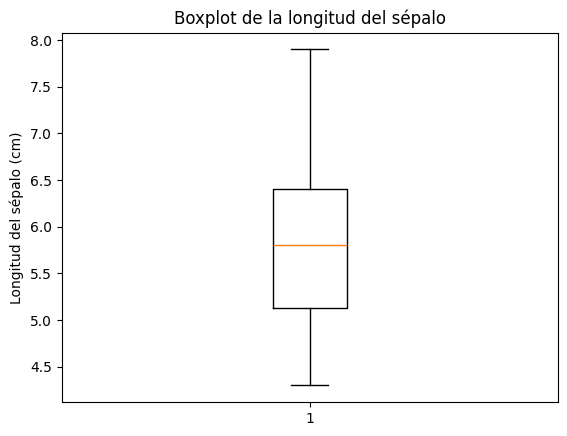

In [38]:
plt.boxplot(df_imputado["sepal length (cm)"])

plt.title("Boxplot de la longitud del sépalo")
plt.ylabel("Longitud del sépalo (cm)")

plt.show()

La línea de la caja es la mediana. Los bigotes terminan en las observaciones más extremas que aún quedan dentro de los límites IQR. Los puntos exteriores quedan señalados para revisión.

**Q1 (25 %)	Primer cuartil**: deja aproximadamente el 25 % de los valores por debajo.

**Mediana (50 %)**:	Valor central de los datos ordenados.

**Q3 (75 %)	Tercer cuartil**: deja aproximadamente el 75 % por debajo.

**Caja**:	Representa el 50 % central de las observaciones.

**Bigotes**	:Se extienden hasta los valores más extremos dentro del criterio utilizado.

**Puntos exteriores**	Posibles valores atípicos.

In [39]:
Q1 = df_imputado["sepal length (cm)"].quantile(0.25)
Q3 = df_imputado["sepal length (cm)"].quantile(0.75)

IQR = Q3 - Q1

print("Primer cuartil:", Q1)
print("Tercer cuartil:", Q3)
print("Rango intercuartílico:", IQR)

Primer cuartil: 5.125
Tercer cuartil: 6.4
Rango intercuartílico: 1.2750000000000004


**.quantile(0.25)** obtiene el primer cuartil (Q1).

**.quantile(0.75)** obtiene el tercer cuartil (Q3).

**Q3 - Q1** calcula la amplitud del intervalo que contiene el 50 % central de los datos.

In [40]:
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Límite inferior: 3.2124999999999995
Límite superior: 8.3125


Primero calculo IQR = Q3 − Q1. Luego resto 1,5 × IQR a Q1 y sumo 1,5 × IQR a Q3. Estos límites señalan candidatos a valores atípicos.

In [41]:
outliers = df_imputado[
    (df_imputado["sepal length (cm)"] < limite_inferior) |
    (df_imputado["sepal length (cm)"] > limite_superior)
]

print("Número de outliers:", len(outliers))

display(outliers)

Número de outliers: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target


`< limite_inferior`: busca medidas inferiores al límite.

`> limite_superior`: busca medidas superiores al límite.


`|`: representa el operador lógico OR (o). Basta con cumplir una de las dos condiciones.

`df_imputado[...]`: filtra las filas que cumplen alguna condición.


`len(outliers)`: cuenta cuántas filas han sido identificadas.

,Medida,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos
0,sepal length (cm),5.125,6.4,1.275,3.2125,8.3125,0
1,sepal width (cm),2.800,3.3,0.500,2.0500,4.0500,4
2,petal length (cm),1.600,5.1,3.500,-3.6500,10.3500,0
3,petal width (cm),0.300,1.8,1.500,-1.9500,4.0500,0


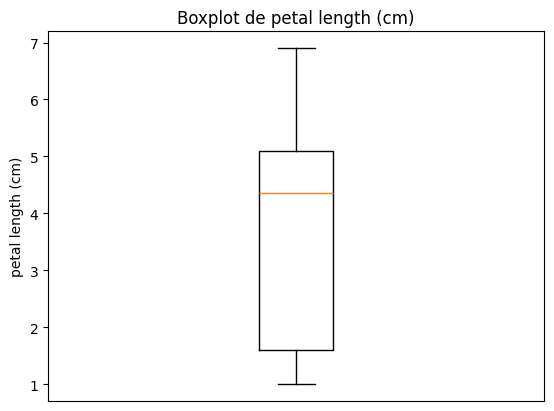

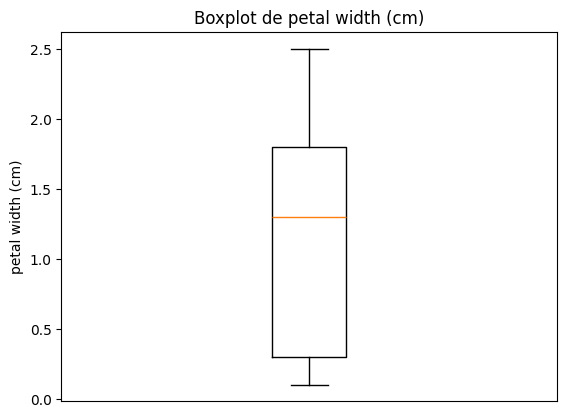

In [42]:
resumen_iqr = []
for columna in columnas_numericas:
    valores = df_imputado[columna]
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    cantidad = ((valores < inferior) | (valores > superior)).sum()
    resumen_iqr.append([columna, q1, q3, iqr, inferior, superior, cantidad])

display(pd.DataFrame(resumen_iqr, columns=[
    "Medida", "Q1", "Q3", "IQR", "Límite inferior", "Límite superior", "Atípicos"
]).round(4))

for columna in columnas_numericas[2:]:
    plt.figure()
    plt.boxplot(df_imputado[columna])
    plt.title(f"Boxplot de {columna}")
    plt.ylabel(columna)
    plt.xticks([])
    plt.show()

## 11. Decisión sobre valores atípicos

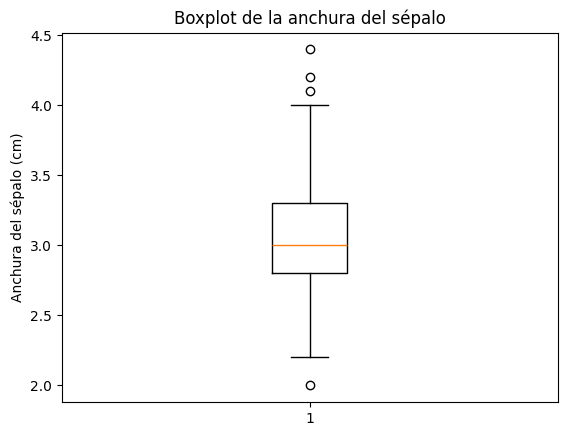

In [43]:
plt.boxplot(df_imputado["sepal width (cm)"])

plt.title("Boxplot de la anchura del sépalo")
plt.ylabel("Anchura del sépalo (cm)")

plt.show()

In [44]:
columna = "sepal width (cm)"

Q1 = df_imputado[columna].quantile(0.25)
Q3 = df_imputado[columna].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df_imputado[
    (df_imputado[columna] < limite_inferior) |
    (df_imputado[columna] > limite_superior)
]

display(outliers)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
15,5.7,4.4,1.5,0.4,0.0
32,5.2,4.1,1.5,0.1,0.0
33,5.5,4.2,1.4,0.2,0.0
60,5.0,2.0,3.5,1.0,1.0


Conservo las cuatro anchuras señaladas (2,0; 4,1; 4,2 y 4,4 cm). Son medidas positivas y plausibles en esta muestra. Estar fuera de los bigotes identifica un extremo estadístico. Corregirlo requeriría evidencia en la fuente. Eliminar o limitar los valores reduciría la variabilidad observada. Resultado de esta revisión: 0 valores cambiados y 0 filas eliminadas.

## 12. Gráfico de dispersión

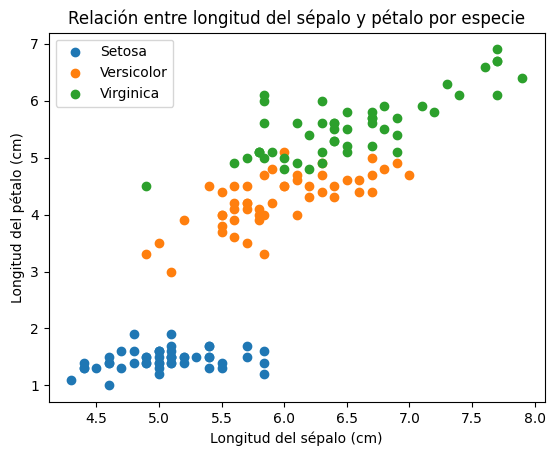

In [45]:
import matplotlib.pyplot as plt

nombres_especies = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}

for especie in sorted(df_imputado["target"].unique()):
    datos_especie = df_imputado[df_imputado["target"] == especie]

    plt.scatter(
        datos_especie["sepal length (cm)"],
        datos_especie["petal length (cm)"],
        label=nombres_especies[especie]
    )

plt.title("Relación entre longitud del sépalo y pétalo por especie")
plt.xlabel("Longitud del sépalo (cm)")
plt.ylabel("Longitud del pétalo (cm)")
plt.legend()
plt.show()

Este gráfico nos permite observar si existe alguna relación entre ambas medidas, identificar agrupaciones y detectar valores aislados.

El gráfico de dispersión muestra una relación positiva entre la longitud del sépalo y la del pétalo: generalmente, cuando aumenta una, también aumenta la otra.

Cada punto representa una flor y sus medidas en centímetros. Se observan distintas agrupaciones que podrían estar relacionadas con las especies de Iris.

La relación no es perfecta y el gráfico por sí solo no demuestra causalidad ni permite identificar errores en las mediciones.

Según la leyenda, Setosa forma un grupo claro de pétalos cortos. Versicolor y Virginica se acercan y se solapan en parte. La alineación vertical cerca de 5,84 cm refleja que diez flores comparten una longitud del sépalo imputada.

## 13. Histogramas por especie

Un análisis bivariante estudia la relación entre dos variables.

Para nuestro ejercicio utilizaremos:
- petal length (cm): variable numérica continua que representa la longitud del pétalo.
- target: variable categórica nominal que identifica la especie.
Queremos responder a esta pregunta: ¿Tienen las tres especies de Iris la misma distribución de longitudes de pétalo?

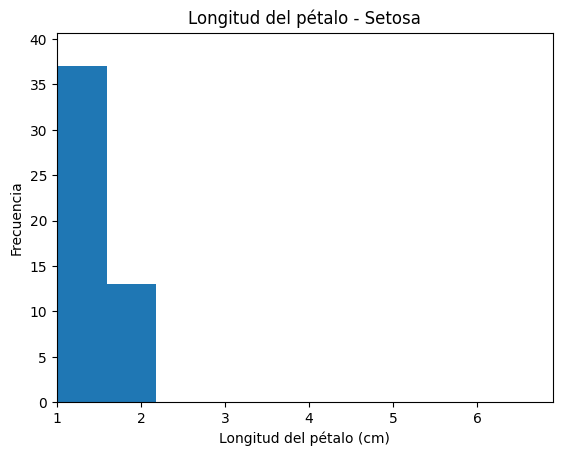

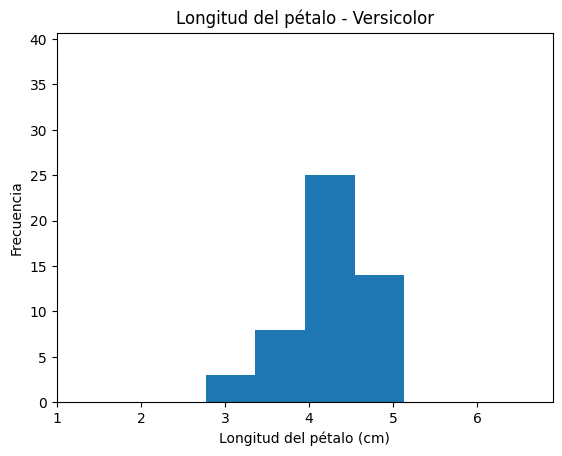

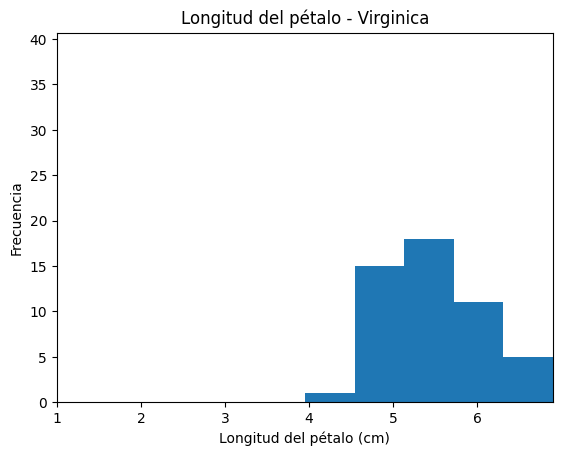

In [46]:
import numpy as np
import matplotlib.pyplot as plt

especies = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}

bins = np.linspace(
    df_imputado["petal length (cm)"].min(),
    df_imputado["petal length (cm)"].max(),
    11
)

mayor_frecuencia = max(
    np.histogram(
        df_imputado.loc[df_imputado["target"] == codigo, "petal length (cm)"],
        bins=bins,
    )[0].max()
    for codigo in especies
)

for codigo, nombre in especies.items():

    datos = df_imputado[
        df_imputado["target"] == codigo
    ]["petal length (cm)"]

    plt.hist(datos, bins=bins)

    plt.title(f"Longitud del pétalo - {nombre}")
    plt.xlabel("Longitud del pétalo (cm)")
    plt.ylabel("Frecuencia")
    plt.xlim(bins[0], bins[-1])
    plt.ylim(0, mayor_frecuencia * 1.1)

    plt.show()


`especies = {...}`	Relaciona cada código con el nombre de la especie.

`np.linspace()`	Genera límites de intervalos equidistantes.

`11`	Genera 11 límites que forman 10 intervalos.

`.items()`	Permite recorrer los códigos y nombres del diccionario.

`df_imputado["target"] == codigo`	Filtra las flores de una especie.

`plt.hist()`	Genera el histograma de esa especie.

`plt.xlim()`	Mantiene la misma escala horizontal en los tres gráficos.

`plt.ylim()`	Mantiene la misma escala vertical.

Usamos los mismos bins porque queremos que las diferencias entre gráficos reflejen diferencias reales en los datos y no cambios en la representación.

En nuestro dataset tenemos 50 flores de cada especie. Por eso podemos comparar directamente las frecuencias de sus histogramas.

Pero imagina que tuviéramos:

Especie	   Número de flores

Setosa	50

Versicolor	100

Virginica	200

En este caso, comparar únicamente las frecuencias podría resultar engañoso, porque los grupos tienen tamaños diferentes.

Para solucionarlo podemos utilizar densidades, que permiten comparar las distribuciones sin depender directamente del número de observaciones.

En Matplotlib podemos hacerlo con el parámetro density=True:

`plt.hist(datos, bins=bins, density=True)`



Este parámetro hace que el área total de las barras del histograma sea 1. No significa que la altura de cada barra sea un porcentaje.

Los tres grupos de los datos tratados tienen 50 flores porque recuperé las cinco etiquetas originales. Setosa concentra los pétalos más cortos, Virginica tiende a tener los más largos y Versicolor y Virginica muestran cierto solapamiento. El histograma global revela concentraciones, mientras que los histogramas por especie permiten atribuirlas a los grupos. Un boxplot por especie permitiría comparar medianas, dispersión y solapamiento con menos espacio.

## 14. Estandarización

¿Qué es la estandarización?

La estandarización es una transformación matemática que permite expresar los valores de distintas variables en una escala comparable.

Por ejemplo, imaginemos dos variables:
- Longitud del sépalo: media de 5.8 cm.
- Longitud del pétalo: media de 3.7 cm.
Aunque ambas estén medidas en centímetros, sus distribuciones pueden ser diferentes.

La estandarización transforma los valores para que cada variable tenga aproximadamente:
- Media = 0
- Desviación estándar = 1
Esto resulta útil en determinados algoritmos de Machine Learning que son sensibles a las escalas de las variables.

z = (valor original - media de la variable) / desviacion estándar

Ej:

`z = (7 − 5,8) / 0,8 = 1,5`

Significa que la longitud del sépalo de esa flor está 1.5 desviaciones estándar por encima de la media.
- z = 0: el valor coincide con la media.
- z = 1: está una desviación estándar por encima.
- z = -1: está una desviación estándar por debajo.

In [47]:

df_estandarizado = df_imputado.copy(deep=True)

for columna in columnas_numericas:
    media_columna = df_imputado[columna].mean()
    desviacion = df_imputado[columna].std()

    df_estandarizado[columna] = (
        df_imputado[columna] - media_columna
    ) / desviacion

display(df_estandarizado.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,-0.920989,1.015602,-1.335752,-1.311052,0.0
1,-1.171355,-0.131539,-1.335752,-1.311052,0.0
2,-1.421721,0.327318,-1.392399,-1.311052,0.0
3,-1.546904,0.097889,-1.279104,-1.311052,0.0
4,-1.046172,1.245030,-1.335752,-1.311052,0.0


In [48]:
print(df_estandarizado[columnas_numericas].agg(["mean", "std"]))

      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean       1.421085e-15     -7.579123e-16      -2.842171e-16     -3.789561e-16
std        1.000000e+00      1.000000e+00       1.000000e+00      1.000000e+00


In [49]:
print("ANTES:")
print(df_imputado[columnas_numericas].agg(["mean", "std"]))

print("\nDESPUÉS:")
print(df_estandarizado[columnas_numericas].agg(["mean", "std"]))

ANTES:
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean           5.835714          3.057333           3.758000          1.199333
std            0.798831          0.435866           1.765298          0.762238

DESPUÉS:
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean       1.421085e-15     -7.579123e-16      -2.842171e-16     -3.789561e-16
std        1.000000e+00      1.000000e+00       1.000000e+00      1.000000e+00


La media después del escalado es prácticamente 0 y la desviación muestral es 1. Estandarizar cambia el centro y la escala, y conserva la forma de la distribución. Puede ayudar en métodos basados en distancias, en los que una variable con mayor escala puede dominar el cálculo.

## 15. Escalado min-max

In [50]:

df_normalizado = df_imputado.copy(deep=True)

for columna in columnas_numericas:
    minimo = df_imputado[columna].min()
    maximo = df_imputado[columna].max()

    df_normalizado[columna] = (
        df_imputado[columna] - minimo
    ) / (maximo - minimo)

display(df_normalizado.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,0.222222,0.625000,0.067797,0.041667,0.0
1,0.166667,0.416667,0.067797,0.041667,0.0
2,0.111111,0.500000,0.050847,0.041667,0.0
3,0.083333,0.458333,0.084746,0.041667,0.0
4,0.194444,0.666667,0.067797,0.041667,0.0


Min-max lleva los valores al intervalo [0, 1] restando el mínimo y dividiendo por el rango. Para la primera flor, la longitud del sépalo queda en `(5,1 − 4,3) / (7,9 − 4,3) = 0,2222`. La salida muestra el mismo valor.

Un extremo puede ampliar el rango y comprimir el resto de los valores. La estandarización también es sensible a extremos por su efecto sobre la media y la desviación. Si el rango es cero, se puede representar la columna constante con ceros y documentar esa decisión. En este conjunto las cuatro medidas tienen rango positivo. Mantengo los cm para comunicar medidas de las flores y uso las copias escaladas cuando interesa comparar magnitudes en una escala común.

In [51]:

print(df_normalizado[columnas_numericas].agg(["min", "max", "mean"]))


      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
min            0.000000          0.000000           0.000000          0.000000
max            1.000000          1.000000           1.000000          1.000000
mean           0.426587          0.440556           0.467458          0.458056


Las columnas de la copia escalada conservan los nombres originales para poder comparar las mismas variables en Pearson. Sus valores transformados son adimensionales.

`df_imputado`	Medidas originales en centímetros, con los valores faltantes tratados.

`df_estandarizado`	Variables con media 0 y desviación estándar 1.

`df_normalizado`	Variables transformadas al intervalo de 0 a 1.

## 16. Correlación de Pearson

In [52]:

correlacion = df_imputado[columnas_numericas].corr(method="pearson")

display(correlacion)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.141826,0.841189,0.786214
sepal width (cm),-0.141826,1.000000,-0.428440,-0.366126
petal length (cm),0.841189,-0.428440,1.000000,0.962865
petal width (cm),0.786214,-0.366126,0.962865,1.000000


`.corr()`: calcula las correlaciones entre las columnas.

`method="pearson"`: indica que queremos utilizar el coeficiente de Pearson.

La **correlación de Pearson** mide la fuerza y dirección de una relación lineal entre dos variables.

**+1** Relación lineal positiva perfecta

**Cercana a +1** Relación lineal positiva fuerte

**0**	No existe relación lineal

**Cercana a -1** Relación lineal negativa fuerte

**-1** Relación lineal negativa perfecta

In [53]:
corr_tratada = df_imputado[columnas_numericas].corr(method="pearson")

corr_estandarizado = df_estandarizado[columnas_numericas].corr(method="pearson")

corr_normalizado = df_normalizado[columnas_numericas].corr(method="pearson")

print("CORRELACIÓN TRATADA SIN ESCALAR:")
display(corr_tratada)

print("\n\nCORRELACIÓN ESTANDARIZADA:")
display(corr_estandarizado)

print("\n\nCORRELACIÓN NORMALIZADA:")
display(corr_normalizado)


CORRELACIÓN TRATADA SIN ESCALAR:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.141826,0.841189,0.786214
sepal width (cm),-0.141826,1.000000,-0.428440,-0.366126
petal length (cm),0.841189,-0.428440,1.000000,0.962865
petal width (cm),0.786214,-0.366126,0.962865,1.000000




CORRELACIÓN ESTANDARIZADA:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.141826,0.841189,0.786214
sepal width (cm),-0.141826,1.000000,-0.428440,-0.366126
petal length (cm),0.841189,-0.428440,1.000000,0.962865
petal width (cm),0.786214,-0.366126,0.962865,1.000000




CORRELACIÓN NORMALIZADA:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.141826,0.841189,0.786214
sepal width (cm),-0.141826,1.000000,-0.428440,-0.366126
petal length (cm),0.841189,-0.428440,1.000000,0.962865
petal width (cm),0.786214,-0.366126,0.962865,1.000000


In [54]:
for version in (df_estandarizado, df_normalizado):
    assert version.index.equals(df_imputado.index)

print("Máxima diferencia absoluta al estandarizar:",
      (corr_tratada - corr_estandarizado).abs().to_numpy().max())
print("Máxima diferencia absoluta al aplicar min-max:",
      (corr_tratada - corr_normalizado).abs().to_numpy().max())

corr_sin_imputar = df_original[columnas_numericas].corr(method="pearson")
longitud_sepalo = "sepal length (cm)"
display(pd.DataFrame({
    "Datos originales": corr_sin_imputar[longitud_sepalo],
    "Datos tratados sin escalar": corr_tratada[longitud_sepalo],
}).drop(index=longitud_sepalo).round(6))

Máxima diferencia absoluta al estandarizar: 2.3592239273284576e-15
Máxima diferencia absoluta al aplicar min-max: 2.7755575615628914e-15


,Datos originales,Datos tratados sin escalar
sepal width (cm),-0.117570,-0.141826
petal length (cm),0.871754,0.841189
petal width (cm),0.817941,0.786214


Uso las mismas 150 filas y las mismas cuatro medidas. Excluyo `target` porque el código de especie es nominal. Pearson usa desviaciones respecto a la media, divididas por la dispersión correspondiente. Restar una constante y dividir por un valor positivo deja igual el coeficiente, salvo redondeo. La comparación con los datos originales aísla el efecto de sustituir diez longitudes del sépalo por la media. La restauración de especies no interviene en la matriz y no se eliminaron filas.

## 17. Mapa de calor

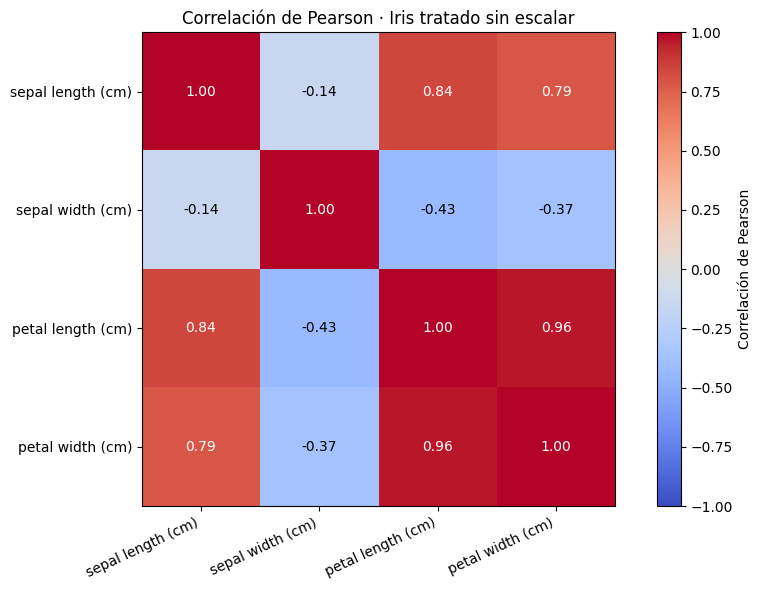

In [55]:
fig, ax = plt.subplots(figsize=(9, 6))
mapa = ax.imshow(corr_tratada, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(mapa, ax=ax, label="Correlación de Pearson")
posiciones = range(len(columnas_numericas))
ax.set_xticks(posiciones, labels=columnas_numericas, rotation=25, ha="right")
ax.set_yticks(posiciones, labels=columnas_numericas)
for fila, valores in enumerate(corr_tratada.to_numpy()):
    for columna, valor in enumerate(valores):
        ax.text(columna, fila, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.7 else "black")
ax.set_title("Correlación de Pearson · Iris tratado sin escalar")
fig.tight_layout()
plt.show()

Cada celda contiene el coeficiente de dos medidas de los datos tratados sin escalar. La diagonal compara cada variable consigo misma y vale 1. El signo indica la dirección y el valor absoluto indica la fuerza de la asociación lineal. Cerca de −1 hay una relación lineal negativa fuerte. Cerca de +1 hay una relación lineal positiva fuerte. Cerca de cero puede haber poca relación lineal y aun así existir un patrón no lineal.

- **Longitud y anchura del pétalo (r ≈ +0,963).** Los pétalos más largos suelen ser más anchos. La relación lineal global es positiva y muy fuerte.
- **Longitud del sépalo y longitud del pétalo (r ≈ +0,841).** Las flores con sépalos más largos tienden a tener pétalos más largos.
- **Anchura del sépalo y longitud del pétalo (r ≈ −0,428).** Las flores con sépalos más anchos tienden a presentar pétalos más cortos, con una asociación negativa moderada.

Pearson es sensible a extremos y resume relaciones lineales. La mezcla de especies puede reforzar o debilitar las asociaciones globales. Que dos medidas varíen juntas en esta muestra no permite concluir que una cause la otra.

## 18. Prompts, fuentes y conclusiones

### Prompts documentados



- **Inicio del ejercicio.** «ayudame con está actividad puno a  por punto explicandome como lo tengo que hacer, por que». Se adjuntó el enunciado del ejercicio.


### Fuentes de contraste de esta revisión

- Enunciado del ejercicio, `subject_eda_colab.pdf`.
- Dataset, tamaño, categorías y carga desde la biblioteca. [Documentación de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)
- Cálculo por pares de columnas y tratamiento de ausencias al calcular la correlación. [Documentación de pandas](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)

### Hallazgos, decisiones y limitaciones

Setosa se distingue por la longitud corta de sus pétalos. Versicolor y Virginica se solapan parcialmente en esa medida. La asociación lineal global más fuerte se da entre la longitud y la anchura del pétalo (r ≈ 0,963). Esa asociación describe la muestra y puede depender en parte de las diferencias entre especies.

Conservo las dos filas con valores idénticos y los cuatro extremos plausibles en anchura del sépalo. Simulo ausencias para practicar el tratamiento, recupero las cinco especies a partir de los datos originales y relleno diez longitudes del sépalo con la media. Ese relleno reduce la dispersión de 0,8271 a 0,7988 cm e influye en las correlaciones que incluyen esta medida. Los resultados de la simulación corresponden a una selección concreta y no estiman el comportamiento ante ausencias reales. El conjunto contiene 150 flores de tres especies y no permite generalizar a otras poblaciones ni establecer causalidad.